<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%BF%D1%80%D0%BE%D0%B4%D0%B2%D0%B8%D0%BD%D1%83%D1%82%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%966.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [1]:
%pip install -q ucimlrepo scikit-fuzzy

import time
import operator
import functools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from scipy.optimize import differential_evolution

import skfuzzy as fuzz
from skfuzzy import control as ctrl

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')

# Завдання 1. Дані Chronic Kidney Disease

> Завантажити та проаналізувати Chronic Kidney Disease Dataset.

In [ ]:
dataset = fetch_ucirepo(id=336)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

print(X.shape)
print(X.head())
print(X.dtypes)
print(y.head())
print("Значення цілі до очищення:", y.iloc[:, 0].value_counts(dropna=False).to_dict())
for col in ["dm", "rbc"]:
    print(col, X[col].value_counts(dropna=False).to_dict())

(400, 24)
    age    bp     sg   al   su     rbc        pc         pcc          ba  \
0  48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent   
1   7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent   
2  62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent   
3  48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent   
4  51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent   

     bgr  ...  hemo   pcv    wbcc  rbcc  htn   dm  cad  appet   pe  ane  
0  121.0  ...  15.4  44.0  7800.0   5.2  yes  yes   no   good   no   no  
1    NaN  ...  11.3  38.0  6000.0   NaN   no   no   no   good   no   no  
2  423.0  ...   9.6  31.0  7500.0   NaN   no  yes   no   poor   no  yes  
3  117.0  ...  11.2  32.0  6700.0   3.9  yes   no   no   poor  yes  yes  
4  106.0  ...  11.6  35.0  7300.0   4.6   no   no   no   good   no   no  

[5 rows x 24 columns]
age      float64
bp       float64
sg       float64
al       float6

Набір містить 400 пацієнтів і 24 ознаки (14 числових і 10 категоріальних), а цільова змінна `class` має значення `ckd` і `notckd`. У даних є технічні дефекти, які треба виправити перед використанням: у цілі два значення `ckd\t` (з символом табуляції), а в ознаці `dm` значення `\tno`. Після `strip()` ці значення зливаються з основними, і клас `ckd` налічує 250 пацієнтів проти 150 `notckd`. Пропущені значення `?` перетворюються на NaN.

In [ ]:
text_cols = X.columns[~X.dtypes.map(pd.api.types.is_numeric_dtype)]
for col in text_cols:
    X[col] = (
        X[col]
        .astype(str)
        .str.strip()
        .replace({"?": np.nan, "nan": np.nan})
    )

target_col = y.columns[0]
y = (
    y[target_col]
    .astype(str)
    .str.strip()
    .str.replace("\t", "", regex=False)
    .map({"ckd": 1, "notckd": 0})
)

valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).reset_index(drop=True)

print(y.value_counts())
print(y.value_counts(normalize=True))
print(X.isna().mean().sort_values(ascending=False).head(10))
print("Текстові (категоріальні) стовпці:", list(text_cols))
print("Числових стовпців:", X.shape[1] - len(text_cols))
print("Рядків із хоча б одним пропуском:", int(X.isna().any(axis=1).sum()), "з", len(X))
print("dm після очищення:", X["dm"].value_counts(dropna=False).to_dict())
print(X[["age", "bgr", "sc", "hemo"]].describe().T)
print(X[["age", "bgr", "sc", "hemo"]].isna().sum().to_dict())

class
1    250
0    150
Name: count, dtype: int64
class
1    0.625
0    0.375
Name: proportion, dtype: float64
rbc     0.3800
rbcc    0.3275
wbcc    0.2650
pot     0.2200
sod     0.2175
pcv     0.1775
pc      0.1625
hemo    0.1300
su      0.1225
sg      0.1175
dtype: float64
Текстові (категоріальні) стовпці: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']
Числових стовпців: 14
Рядків із хоча б одним пропуском: 242 з 400
dm після очищення: {'no': 261, 'yes': 137, nan: 2}
      count        mean        std   min   25%     50%    75%    max
age   391.0   51.483376  17.169714   2.0  42.0   55.00   64.5   90.0
bgr   356.0  148.036517  79.281714  22.0  99.0  121.00  163.0  490.0
sc    383.0    3.072454   5.741126   0.4   0.9    1.30    2.8   76.0
hemo  348.0   12.526437   2.912587   3.1  10.3   12.65   15.0   17.8
{'age': 9, 'bgr': 44, 'sc': 17, 'hemo': 52}


Клас `ckd` становить 62.5%, `notckd` 37.5%, тобто баланс помірний. Пропуски є у багатьох ознаках: найбільше в `rbc` (38%), `rbcc` (32.8%), `wbcc` (26.5%), `pot` (22%), `sod` (21.8%), і 242 із 400 рядків мають хоча б один пропуск. Для чотирьох ознак fuzzy-компонента пропусків небагато: `age` 9, `bgr` 44, `sc` 17, `hemo` 52. Розподіли дуже скошені: наприклад, `sc` має медіану 1.3, а максимум 76 (при універсумі fuzzy-змінної 0 – 16), тому для fuzzy-компонента значення обрізаються до меж універсуму.

# Завдання 2. Split та preprocessing

> Побудувати preprocessing для mixed-type data без leakage.

In [ ]:
def make_split(seed=42):
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y,
        test_size=0.20,
        stratify=y,
        random_state=seed
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.25,
        stratify=y_train_full,
        random_state=seed
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

X_train, X_val, X_test, y_train, y_val, y_test = make_split(42)

print("Train:", X_train.shape, ", ckd:", int(y_train.sum()))
print("Validation:", X_val.shape, ", ckd:", int(y_val.sum()))
print("Test:", X_test.shape, ", ckd:", int(y_test.sum()))

def build_preprocessor(frame):
    numeric_cols = frame.select_dtypes(include="number").columns.tolist()
    categorical_cols = [c for c in frame.columns if c not in numeric_cols]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric_cols),
        ("cat", categorical_pipe, categorical_cols)
    ])

preprocessor = build_preprocessor(X_train)
print("Числових:", len(preprocessor.transformers[0][2]), ", категоріальних:", len(preprocessor.transformers[1][2]))
print("Ознак після кодування:", preprocessor.fit(X_train).transform(X_train).shape[1])

Train: (240, 24) , ckd: 150
Validation: (80, 24) , ckd: 50
Test: (80, 24) , ckd: 50
Числових: 14 , категоріальних: 10
Ознак після кодування: 34


Дані розбито стратифіковано на навчальну (240), валідаційну (80) і тестову (80) частини, у кожній 62.5% класу `ckd` (150, 50 і 50 пацієнтів). Тест не використовується ані для навчання нейронної мережі, ані для підбору α і порогу. Препроцесор (медіана і стандартизація для числових, найчастіше значення і One-Hot для категоріальних) входить до `Pipeline` і навчається лише на навчальній частині; після кодування залишається 34 ознаки. Оскільки в наборі лише 80 пацієнтів у кожній з оцінюваних частин (30 здорових і 50 хворих у тесті), одна помилка змінює BAcc приблизно на 1 – 1.7 п.п.

# Завдання 3. Neural Component

> Навчити Neural Component на повному наборі доступних ознак.

In [ ]:
def make_neural(hidden=(32, 16), seed=42):
    return Pipeline([
        ("prep", build_preprocessor(X_train)),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=hidden,
            activation="relu",
            alpha=1e-3,
            max_iter=1500,
            early_stopping=True,
            random_state=seed
        ))
    ])

neural_model = make_neural()
neural_model.fit(X_train, y_train)

p_nn_val = neural_model.predict_proba(X_val)[:, 1]
p_nn_test = neural_model.predict_proba(X_test)[:, 1]

print("NN validation ROC-AUC:", roc_auc_score(y_val, p_nn_val))
print("NN test ROC-AUC:", roc_auc_score(y_test, p_nn_test))
print("Ітерацій навчання:", neural_model.named_steps["mlp"].n_iter_)
print("Кількість параметрів:", sum(w.size for w in neural_model.named_steps["mlp"].coefs_) + sum(b.size for b in neural_model.named_steps["mlp"].intercepts_))

NN validation ROC-AUC: 0.99
NN test ROC-AUC: 0.9986666666666667
Ітерацій навчання: 27
Кількість параметрів: 1665


Нейронна мережа (32, 16) із ранньою зупинкою після 27 ітерацій має 1665 параметрів і дає ROC-AUC 0.990 на validation та 0.9987 на тесті. Тобто навіть мала мережа майже ідеально розділяє класи, і для fuzzy-компонента та гібридизації залишається небагато простору для покращення.

# Завдання 4. Fuzzy Component

> Побудувати Fuzzy Component з чотирма клінічними факторами.

In [ ]:
fuzzy_cols = ["age", "bgr", "sc", "hemo"]

medians = {col: pd.to_numeric(X_train[col], errors="coerce").median() for col in fuzzy_cols}
print("Медіани за навчальною частиною:", medians)

def fuzzy_frame(frame, medians):
    out = frame[fuzzy_cols].apply(pd.to_numeric, errors="coerce")
    return out.fillna(pd.Series(medians))

fz_train = fuzzy_frame(X_train, medians)
fz_val = fuzzy_frame(X_val, medians)
fz_test = fuzzy_frame(X_test, medians)

Медіани за навчальною частиною: {'age': np.float64(51.5), 'bgr': np.float64(120.0), 'sc': np.float64(1.3), 'hemo': np.float64(12.6)}


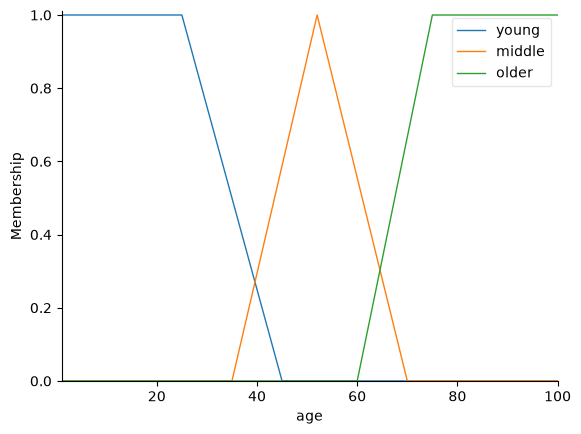

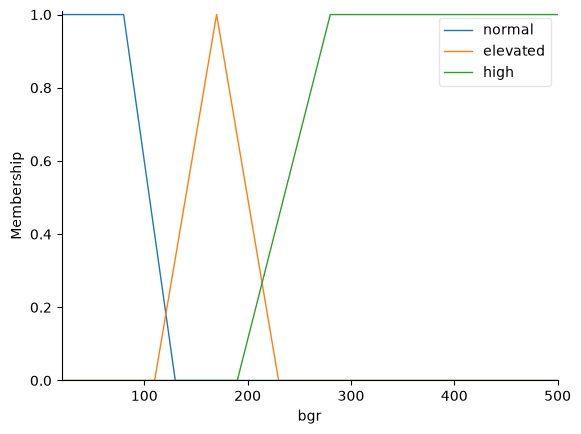

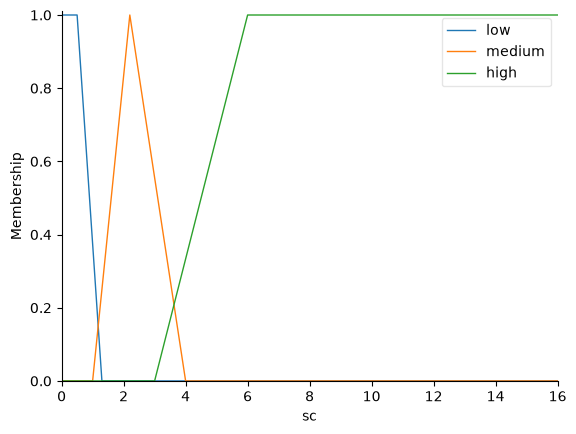

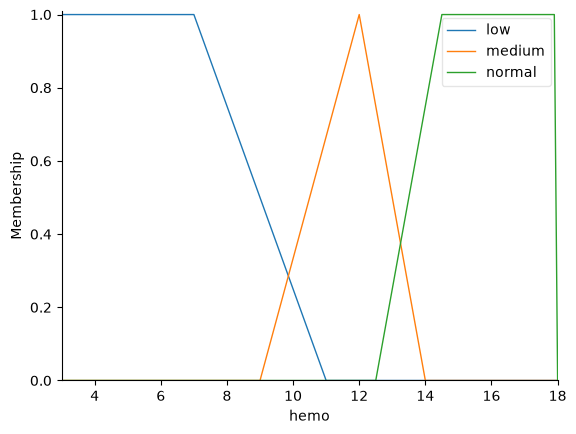

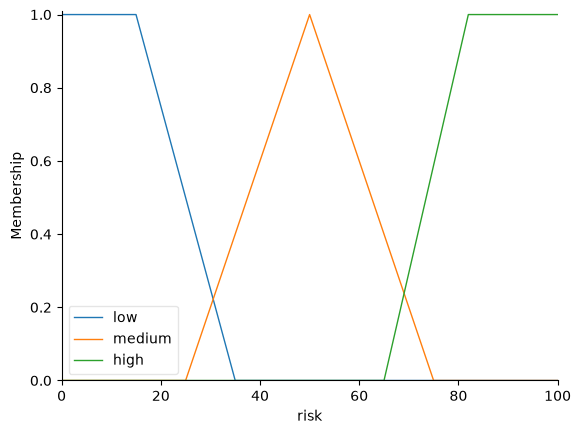

In [ ]:
age = ctrl.Antecedent(np.arange(1, 101, 1), "age")
bgr = ctrl.Antecedent(np.arange(20, 501, 2), "bgr")
sc = ctrl.Antecedent(np.arange(0, 16.1, 0.1), "sc")
hemo = ctrl.Antecedent(np.arange(3, 18.1, 0.1), "hemo")

risk = ctrl.Consequent(np.arange(0, 101, 1), "risk")

age["young"] = fuzz.trapmf(age.universe, [1, 1, 25, 45])
age["middle"] = fuzz.trimf(age.universe, [35, 52, 70])
age["older"] = fuzz.trapmf(age.universe, [60, 75, 100, 100])

bgr["normal"] = fuzz.trapmf(bgr.universe, [20, 20, 80, 130])
bgr["elevated"] = fuzz.trimf(bgr.universe, [110, 170, 230])
bgr["high"] = fuzz.trapmf(bgr.universe, [190, 280, 500, 500])

sc["low"] = fuzz.trapmf(sc.universe, [0, 0, 0.5, 1.3])
sc["medium"] = fuzz.trimf(sc.universe, [1.0, 2.2, 4.0])
sc["high"] = fuzz.trapmf(sc.universe, [3.0, 6.0, 16.0, 16.0])

hemo["low"] = fuzz.trapmf(hemo.universe, [3, 3, 7, 11])
hemo["medium"] = fuzz.trimf(hemo.universe, [9, 12, 14])
hemo["normal"] = fuzz.trapmf(hemo.universe, [12.5, 14.5, 18, 18])

risk["low"] = fuzz.trapmf(risk.universe, [0, 0, 15, 35])
risk["medium"] = fuzz.trimf(risk.universe, [25, 50, 75])
risk["high"] = fuzz.trapmf(risk.universe, [65, 82, 100, 100])

age.view()
bgr.view()
sc.view()
hemo.view()
risk.view()
plt.show()

Функції належності є навчальною конфігурацією, а не клінічними межами. База з 10 правил:

| № | Правило | Пояснення |
|---|---------|-----------|
| 1 | IF sc low AND hemo normal THEN risk low | низький креатинін і нормальний гемоглобін |
| 2 | IF sc low AND bgr normal AND hemo medium THEN risk low | низький креатинін і норма глюкози, гемоглобін помірний |
| 3 | IF sc medium AND hemo medium THEN risk medium | обидва показники в проміжній зоні |
| 4 | IF bgr elevated AND hemo medium THEN risk medium | підвищена глюкоза і помірний гемоглобін |
| 5 | IF age older AND sc medium THEN risk medium | старший вік підсилює проміжний креатинін |
| 6 | IF sc high THEN risk high | високий креатинін сам по собі |
| 7 | IF hemo low THEN risk high | низький гемоглобін сам по собі |
| 8 | IF sc medium AND hemo low THEN risk high | поєднання проміжного креатиніну і низького гемоглобіну |
| 9 | IF sc high AND bgr high THEN risk high | високий креатинін разом із високою глюкозою |
| 10 | IF age older AND hemo low THEN risk high | старший вік і низький гемоглобін |

In [ ]:
rules = [
    ctrl.Rule(sc["low"] & hemo["normal"], risk["low"]),
    ctrl.Rule(sc["low"] & bgr["normal"] & hemo["medium"], risk["low"]),

    ctrl.Rule(sc["medium"] & hemo["medium"], risk["medium"]),
    ctrl.Rule(bgr["elevated"] & hemo["medium"], risk["medium"]),
    ctrl.Rule(age["older"] & sc["medium"], risk["medium"]),

    ctrl.Rule(sc["high"], risk["high"]),
    ctrl.Rule(hemo["low"], risk["high"]),
    ctrl.Rule(sc["medium"] & hemo["low"], risk["high"]),
    ctrl.Rule(sc["high"] & bgr["high"], risk["high"]),
    ctrl.Rule(age["older"] & hemo["low"], risk["high"])
]

fuzzy_system = ctrl.ControlSystem(rules)

def fuzzy_probability(row):
    sim = ctrl.ControlSystemSimulation(fuzzy_system)

    sim.input["age"] = np.clip(row["age"], 1, 100)
    sim.input["bgr"] = np.clip(row["bgr"], 20, 500)
    sim.input["sc"] = np.clip(row["sc"], 0, 16)
    sim.input["hemo"] = np.clip(row["hemo"], 3, 18)

    try:
        sim.compute()
        return round(float(sim.output["risk"]), 6) / 100.0
    except Exception:
        return 0.5

p_fuzzy_val = fz_val.apply(fuzzy_probability, axis=1).to_numpy()
p_fuzzy_test = fz_test.apply(fuzzy_probability, axis=1).to_numpy()

print("Fuzzy validation ROC-AUC:", roc_auc_score(y_val, p_fuzzy_val))
print("Fuzzy test ROC-AUC:", roc_auc_score(y_test, p_fuzzy_test))
print("Частка значень рівно 0.5 (validation):", (p_fuzzy_val == 0.5).mean(), ", test:", (p_fuzzy_test == 0.5).mean())

Fuzzy validation ROC-AUC: 0.9639999999999999
Fuzzy test ROC-AUC: 0.9483333333333333
Частка значень рівно 0.5 (validation): 0.175 , test: 0.2125


Fuzzy-компонент використовує чотири входи та 10 правил із теорії; його ROC-AUC 0.964 на validation і 0.948 на тесті. Медіани для заповнення пропусків (age 51.5, bgr 120, sc 1.3, hemo 12.6) обчислено лише на навчальній частині. Особливості виходу: частка значень рівно 0.5 становить 17.5% на validation і 21.3% на тесті. Це випадки, коли спрацьовують лише правила з висновком medium (центроїд симетричного трикутника дорівнює 50), або жодне правило не спрацювало, і тоді згідно з теорією повертається значення 0.5 (на тесті таким є 1 пацієнт із 80, на validation покрито всіх). Ризик округлено до 6 знаків, щоб порівняння з порогом не залежало від похибок обчислень.

# Завдання 5. Neural-only та Fuzzy-only на validation set

> Порівняти Neural-only та Fuzzy-only на validation set.

In [ ]:
def metrics(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    return {
        "Model": name,
        "Threshold": round(float(threshold), 4),
        "BAcc": balanced_accuracy_score(y_true, pred),
        "Sensitivity": recall_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "FP": int(fp), "FN": int(fn)
    }

print(pd.DataFrame([
    metrics("Neural", y_val, p_nn_val),
    metrics("Fuzzy", y_val, p_fuzzy_val)
]).round(4).to_string(index=False))

 Model  Threshold   BAcc  Sensitivity  Precision     F1  ROC_AUC  FP  FN
Neural        0.5 0.9733         0.98     0.9800 0.9800    0.990   1   1
 Fuzzy        0.5 0.8833         0.80     0.9756 0.8791    0.964   1  10


На validation (80 пацієнтів) нейронна мережа при порозі 0.5 має BAcc 0.9733, sensitivity 0.98 і F1 0.980 (1 хибнопозитивний і 1 пропущений), ROC-AUC 0.990. Fuzzy-система поступається: BAcc 0.8833, sensitivity 0.80, F1 0.879 (1 хибнопозитивний і 10 пропущених хворих), ROC-AUC 0.964. Тобто fuzzy-компонент здебільшого впорядковує пацієнтів досить добре (AUC 0.964), але при порозі 0.5 пропускає кожного п'ятого хворого.

# Завдання 6. Decision-level fusion та Differential Evolution

> Реалізувати decision-level fusion. Оптимізувати alpha та threshold за допомогою Differential Evolution.

In [ ]:
def fusion_objective(params):
    alpha, threshold = params

    p_hybrid = (
        alpha * p_nn_val +
        (1.0 - alpha) * p_fuzzy_val
    )

    pred = (p_hybrid >= threshold).astype(int)
    bacc = balanced_accuracy_score(y_val, pred)

    return 1.0 - bacc

t0 = time.time()
result = differential_evolution(
    fusion_objective,
    bounds=[
        (0.0, 1.0),
        (0.10, 0.90)
    ],
    seed=42,
    popsize=15,
    maxiter=50,
    polish=True
)
de_time = time.time() - t0

best_alpha, best_threshold = result.x

print("Best alpha:", best_alpha)
print("Best threshold:", best_threshold)
print("Validation BAcc:", 1.0 - result.fun)
print("Evaluations:", result.nfev, ", iterations:", result.nit, ", time, s:", round(de_time, 2))
print("Success:", result.success, ",", result.message)

Best alpha: 0.7135136333583466
Best threshold: 0.4844167362209938
Validation BAcc: 0.99
Evaluations: 363 , iterations: 11 , time, s: 0.19
Success: True , Optimization terminated successfully.


Differential Evolution знайшов α = 0.7135 і threshold = 0.4844 із validation BAcc 0.99 (363 оцінки, 11 ітерацій, 0.19 с). Тобто в сумі 71% ваги припадає на нейронну мережу і 29% на fuzzy. Objective-функція кусково-стала (BAcc змінюється стрибками), тому багато точок дають однакове значення 0.99 (див. карту нижче), і знайдені α та threshold це одна з багатьох рівноцінних точок, а не єдиний оптимум; `polish=True` на такій функції нічого не змінює.

# Завдання 7. Фінальна Hybrid System на test set

> Оцінити фінальну Hybrid System на untouched test set.

In [ ]:
p_hybrid_val = best_alpha * p_nn_val + (1.0 - best_alpha) * p_fuzzy_val
p_hybrid_test = (
    best_alpha * p_nn_test +
    (1.0 - best_alpha) * p_fuzzy_test
)

final_results = pd.DataFrame([
    metrics("Neural-only", y_test, p_nn_test, 0.5),
    metrics("Fuzzy-only", y_test, p_fuzzy_test, 0.5),
    metrics(
        "Hybrid",
        y_test,
        p_hybrid_test,
        best_threshold
    )
])

print(final_results.round(4).to_string(index=False))

hybrid_pred = (
    p_hybrid_test >= best_threshold
).astype(int)

print(confusion_matrix(y_test, hybrid_pred))
print(classification_report(
    y_test,
    hybrid_pred,
    digits=4
))

      Model  Threshold   BAcc  Sensitivity  Precision     F1  ROC_AUC  FP  FN
Neural-only     0.5000 0.9667         1.00     0.9615 0.9804   0.9987   2   0
 Fuzzy-only     0.5000 0.9300         0.86     1.0000 0.9247   0.9483   0   7
     Hybrid     0.4844 0.9833         1.00     0.9804 0.9901   0.9993   1   0
[[29  1]
 [ 0 50]]
              precision    recall  f1-score   support

           0     1.0000    0.9667    0.9831        30
           1     0.9804    1.0000    0.9901        50

    accuracy                         0.9875        80
   macro avg     0.9902    0.9833    0.9866        80
weighted avg     0.9877    0.9875    0.9875        80



На незалежному тесті Neural-only має BAcc 0.9667 (2 хибнопозитивних, 0 пропущених, F1 0.9804, ROC-AUC 0.9987), Fuzzy-only 0.9300 (0 хибнопозитивних, 7 пропущених, F1 0.9247, ROC-AUC 0.9483), Hybrid 0.9833 (1 хибнопозитивний, 0 пропущених, F1 0.9901, ROC-AUC 0.9993). Матриця помилок гібриду: 29 із 30 здорових і 50 із 50 хворих класифіковано правильно. Перевага гібриду над нейронною мережею дорівнює одному пацієнтові (1 хибнопозитивний проти 2), тому на цьому розбитті її не можна вважати статистично підтвердженою.

# Завдання 8. Карта alpha × threshold та scatter plot

> Побудувати карту alpha × threshold та Neural-vs-Fuzzy scatter plot.

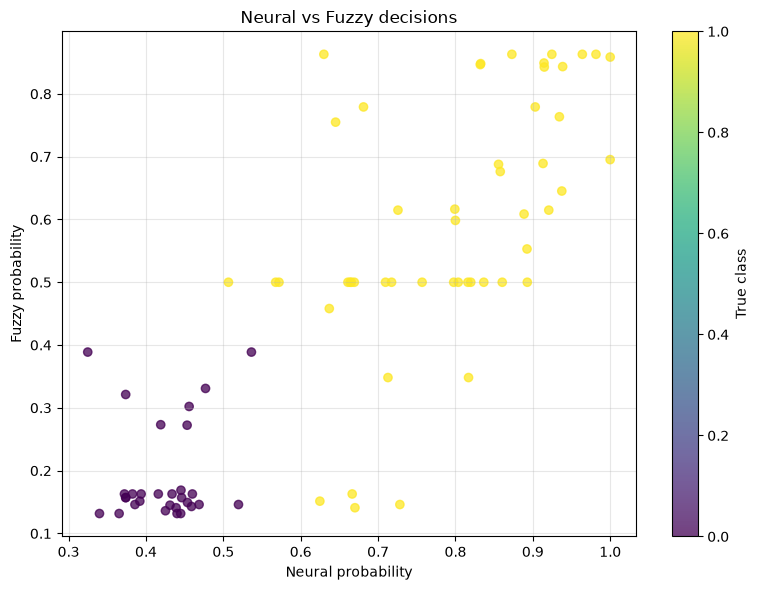

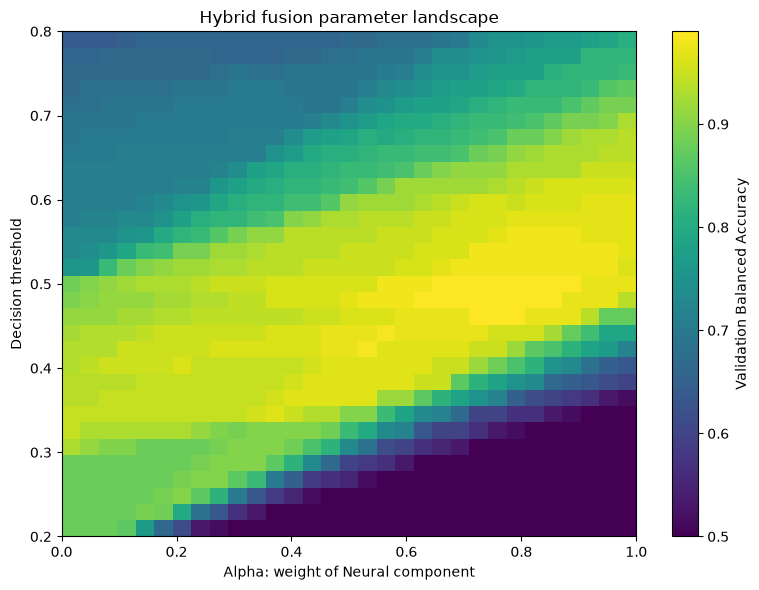

Максимум на карті: 0.99 , клітинок із максимумом: 19 з 961
Мінімум на карті: 0.5
Корелляція p_nn та p_fuzzy (test): 0.8291757706574288
Середнє p_nn: ckd 0.7946140240007784 , notckd 0.42337061116061936
Середнє p_fuzzy: ckd 0.594697417 , notckd 0.19080926666666667


In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    p_nn_test,
    p_fuzzy_test,
    c=y_test,
    alpha=0.75
)
plt.xlabel("Neural probability")
plt.ylabel("Fuzzy probability")
plt.title("Neural vs Fuzzy decisions")
plt.colorbar(label="True class")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

alphas = np.linspace(0, 1, 31)
thresholds = np.linspace(0.2, 0.8, 31)

score_map = np.zeros((len(thresholds), len(alphas)))

for i, t in enumerate(thresholds):
    for j, a in enumerate(alphas):
        p = a * p_nn_val + (1 - a) * p_fuzzy_val
        pred = (p >= t).astype(int)
        score_map[i, j] = balanced_accuracy_score(
            y_val, pred
        )

plt.figure(figsize=(8, 6))
plt.imshow(
    score_map,
    origin="lower",
    aspect="auto",
    extent=[
        alphas.min(), alphas.max(),
        thresholds.min(), thresholds.max()
    ]
)
plt.colorbar(label="Validation Balanced Accuracy")
plt.xlabel("Alpha: weight of Neural component")
plt.ylabel("Decision threshold")
plt.title("Hybrid fusion parameter landscape")
plt.tight_layout()
plt.show()

print("Максимум на карті:", score_map.max(), ", клітинок із максимумом:", int((score_map == score_map.max()).sum()), "з", score_map.size)
print("Мінімум на карті:", score_map.min())
print("Корелляція p_nn та p_fuzzy (test):", np.corrcoef(p_nn_test, p_fuzzy_test)[0, 1])
print("Середнє p_nn: ckd", p_nn_test[y_test.to_numpy() == 1].mean(), ", notckd", p_nn_test[y_test.to_numpy() == 0].mean())
print("Середнє p_fuzzy: ckd", p_fuzzy_test[y_test.to_numpy() == 1].mean(), ", notckd", p_fuzzy_test[y_test.to_numpy() == 0].mean())

Максимальне значення BAcc на validation (0.99) досягається у 19 клітинках із 961, а мінімальне дорівнює 0.5, тобто є широка область рівноцінних комбінацій α і threshold, і вибір точки в ній не має підстав у validation-даних. Прогнози компонентів корелюють (r = 0.83 на тесті): середня ймовірність хворих 0.795 у нейронної мережі і 0.595 у fuzzy-системи, а здорових 0.423 і 0.191. Тобто нейронні ймовірності помірні (мережа не дуже впевнена), а fuzzy-значення нижчі для обох класів, тому для fuzzy оптимальний поріг нижчий за 0.5 (див. експеримент 1).

# Завдання 9. Disagreement cases

> Проаналізувати щонайменше 5 найбільших disagreement cases.

In [ ]:
analysis = fz_test.copy()
analysis["True"] = y_test.to_numpy()
analysis["P_NN"] = p_nn_test
analysis["P_Fuzzy"] = p_fuzzy_test
analysis["P_Hybrid"] = p_hybrid_test
analysis["Difference"] = np.abs(
    analysis["P_NN"] - analysis["P_Fuzzy"]
)

top = analysis.sort_values("Difference", ascending=False).head(10)
print(top.round(3).to_string())

analysis["NN_pred"] = (analysis["P_NN"] >= 0.5).astype(int)
analysis["Fuzzy_pred"] = (analysis["P_Fuzzy"] >= 0.5).astype(int)
analysis["Hybrid_pred"] = (analysis["P_Hybrid"] >= best_threshold).astype(int)
dis = analysis[analysis["NN_pred"] != analysis["Fuzzy_pred"]]
print("Випадків розбіжності рішень NN і Fuzzy при порозі 0.5:", len(dis), "з", len(analysis))
print("Серед них NN правильний:", int((dis["NN_pred"] == dis["True"]).sum()), ", Fuzzy правильний:", int((dis["Fuzzy_pred"] == dis["True"]).sum()), ", Hybrid правильний:", int((dis["Hybrid_pred"] == dis["True"]).sum()))

      age    bgr   sc  hemo  True   P_NN  P_Fuzzy  P_Hybrid  Difference
164  14.0  192.0  0.8  14.3     1  0.728    0.146     0.561       0.582
70   61.0  360.0  0.7  15.2     1  0.670    0.141     0.518       0.529
65   44.0  120.0  1.1  15.0     1  0.666    0.163     0.522       0.504
150   8.0   78.0  0.9  12.3     1  0.625    0.151     0.489       0.473
115  47.0  120.0  0.9  12.4     1  0.817    0.348     0.683       0.469
27   69.0  264.0  2.7  12.5     1  0.893    0.500     0.780       0.393
394  50.0  137.0  0.8  14.1     0  0.520    0.146     0.413       0.374
186   8.0  120.0  1.0  12.6     1  0.713    0.348     0.608       0.365
107  55.0  297.0  2.8  11.2     1  0.860    0.500     0.757       0.360
184  54.0  352.0  3.3  11.3     1  0.892    0.553     0.795       0.339
Випадків розбіжності рішень NN і Fuzzy при порозі 0.5: 9 з 80
Серед них NN правильний: 7 , Fuzzy правильний: 2 , Hybrid правильний: 8


Із 80 тестових пацієнтів рішення NN і Fuzzy при порозі 0.5 різняться у 9 випадках: нейронна мережа права у 7, fuzzy у 2, гібрид у 8. Найбільші розбіжності ймовірностей майже всі стосуються хворих, яких fuzzy-система оцінила низьким ризиком (0.14 – 0.16), а нейронна мережа високим (0.63 – 0.82): наприклад пацієнти 164 (age 14, bgr 192, sc 0.8, hemo 14.3), 70 (sc 0.7, hemo 15.2), 65 (sc 1.1, hemo 15.0) і 150 (sc 0.9, hemo 12.3) мають креатинін і гемоглобін, які правила вважають нормою, тож fuzzy не бачить ознак ризику, а нейронна мережа використовує решту 20 ознак. Пацієнт 394 (здоровий, sc 0.8, hemo 14.1) навпаки: NN дає 0.520 (на межі помилки), а fuzzy правильно 0.146. Пацієнти 27, 107 і 184 (sc 2.7 – 3.3, hemo 11.2 – 12.5) отримують від fuzzy 0.50 – 0.55, тобто проміжний ризик, а від NN 0.86 – 0.89. Тобто fuzzy-компонент помиляється там, де інформація лежить поза його чотирма входами або в зоні, де правила дають лише проміжний ризик, а гібрид виправляє частину таких випадків за рахунок нейронної ваги.

# Завдання 10. Експерименти

> Провести всі експерименти з розділу 21.

> 1. Fusion strategy: Neural-only; Fuzzy-only; average 0.5/0.5; optimized fusion. Що аналізувати: BAcc, F1, ROC-AUC.
> 2. Optimization: ручний grid search vs Differential Evolution. Що аналізувати: якість, кількість evaluations, стабільність.
> 3. Fuzzy ablation: вилучити age або bgr; залишити sc+hemo. Що аналізувати: чи всі експертні inputs реально корисні.
> 4. Rule sensitivity: вилучити 2–3 правила або змінити membership boundaries. Що аналізувати: зміна Fuzzy та Hybrid metrics.
> 5. Neural architecture: (16); (32,16); (64,32,16). Що аналізувати: якість та стабільність.
> 6. Repeated seeds: мінімум 5 random_state для MLP/DE. Що аналізувати: mean ± std, стабільність alpha.

In [ ]:
UNI = {
    "age": np.arange(1, 101, 1),
    "bgr": np.arange(20, 501, 2),
    "sc": np.arange(0, 16.1, 0.1),
    "hemo": np.arange(3, 18.1, 0.1),
    "risk": np.arange(0, 101, 1)
}

MF_BASE = {
    "age": {"young": ("trap", [1, 1, 25, 45]), "middle": ("tri", [35, 52, 70]), "older": ("trap", [60, 75, 100, 100])},
    "bgr": {"normal": ("trap", [20, 20, 80, 130]), "elevated": ("tri", [110, 170, 230]), "high": ("trap", [190, 280, 500, 500])},
    "sc": {"low": ("trap", [0, 0, 0.5, 1.3]), "medium": ("tri", [1.0, 2.2, 4.0]), "high": ("trap", [3.0, 6.0, 16.0, 16.0])},
    "hemo": {"low": ("trap", [3, 3, 7, 11]), "medium": ("tri", [9, 12, 14]), "normal": ("trap", [12.5, 14.5, 18, 18])},
    "risk": {"low": ("trap", [0, 0, 15, 35]), "medium": ("tri", [25, 50, 75]), "high": ("trap", [65, 82, 100, 100])}
}

def R(out, *conds):
    return (conds, out)

RULES_BASE = [
    R("low", ("sc", "low"), ("hemo", "normal")),
    R("low", ("sc", "low"), ("bgr", "normal"), ("hemo", "medium")),
    R("medium", ("sc", "medium"), ("hemo", "medium")),
    R("medium", ("bgr", "elevated"), ("hemo", "medium")),
    R("medium", ("age", "older"), ("sc", "medium")),
    R("high", ("sc", "high")),
    R("high", ("hemo", "low")),
    R("high", ("sc", "medium"), ("hemo", "low")),
    R("high", ("sc", "high"), ("bgr", "high")),
    R("high", ("age", "older"), ("hemo", "low"))
]

def make_mf(kind, params, universe):
    return fuzz.trapmf(universe, params) if kind == "trap" else fuzz.trimf(universe, params)

def build_system(mf, rule_list):
    variables = {}
    for name, terms in mf.items():
        if name == "risk":
            variables[name] = ctrl.Consequent(UNI[name], name)
        else:
            variables[name] = ctrl.Antecedent(UNI[name], name)
        for term, (kind, params) in terms.items():
            variables[name][term] = make_mf(kind, params, UNI[name])
    built = []
    for conds, out in rule_list:
        antecedent = functools.reduce(operator.and_, [variables[v][t] for v, t in conds])
        built.append(ctrl.Rule(antecedent, variables["risk"][out]))
    return ctrl.ControlSystem(built)

def fuzzy_scores(system, frame):
    names = [a.label for a in system.antecedents]
    columns = {n: np.clip(frame[n].to_numpy(float), UNI[n].min(), UNI[n].max()) for n in names}
    out = np.full(len(frame), 0.5)
    covered = np.zeros(len(frame), dtype=bool)
    for k in range(len(frame)):
        sim = ctrl.ControlSystemSimulation(system)
        for n in names:
            sim.input[n] = columns[n][k]
        try:
            sim.compute()
            out[k] = round(float(sim.output["risk"]), 6) / 100.0
            covered[k] = True
        except Exception:
            pass
    return out, covered

def optimize_fusion(p_nn, p_fz, y_true, seed=42):
    y_arr = np.asarray(y_true)

    def objective(params):
        alpha, threshold = params
        pred = ((alpha * p_nn + (1.0 - alpha) * p_fz) >= threshold).astype(int)
        return 1.0 - balanced_accuracy_score(y_arr, pred)

    res = differential_evolution(objective, bounds=[(0.0, 1.0), (0.10, 0.90)], seed=seed, popsize=15, maxiter=50, polish=True)
    return float(res.x[0]), float(res.x[1]), 1.0 - float(res.fun), int(res.nfev)

def hybrid_row(name, alpha, threshold, p_nn, p_fz, y_true):
    return metrics(name, y_true, alpha * p_nn + (1.0 - alpha) * p_fz, threshold)

base_system = build_system(MF_BASE, RULES_BASE)
chk_val, cov_val = fuzzy_scores(base_system, fz_val)
chk_test, cov_test = fuzzy_scores(base_system, fz_test)
print("Різниця з системою із завдання 4 (val, test):", np.abs(chk_val - p_fuzzy_val).max(), np.abs(chk_test - p_fuzzy_test).max())
print("Покрито правилами: validation", int(cov_val.sum()), "з", len(cov_val), ", test", int(cov_test.sum()), "з", len(cov_test))

Різниця з системою із завдання 4 (val, test): 0.0 0.0
Покрито правилами: validation 80 з 80 , test 79 з 80


Допоміжні функції будують fuzzy-систему зі словника функцій належності та списку правил; базові параметри відтворюють систему із завдання 4 (різниця ризиків дорівнює 0). У випадку, коли жодне правило не спрацювало (на тесті 1 пацієнт із 80), повертається 0.5, як у теорії. У експериментах 3 і 4 змінюється лише fuzzy-компонент, а нейронна мережа (32, 16, seed 42) та DE для злиття (α і threshold) перенавчаються на validation для кожного варіанта.

# Експеримент 1. Fusion strategy

In [ ]:
a_opt, t_opt, _, _ = optimize_fusion(p_nn_val, p_fuzzy_val, y_val)

def best_threshold_for(p, y_true):
    ts = np.linspace(0.1, 0.9, 81)
    scores = [balanced_accuracy_score(y_true, (p >= t).astype(int)) for t in ts]
    return float(ts[int(np.argmax(scores))])

t_nn = best_threshold_for(p_nn_val, y_val)
t_fz = best_threshold_for(p_fuzzy_val, y_val)

rows = []
for split_name, yy, pn, pf in [("validation", y_val, p_nn_val, p_fuzzy_val), ("test", y_test, p_nn_test, p_fuzzy_test)]:
    for r in [
        metrics("Neural-only (0.5)", yy, pn, 0.5),
        metrics("Fuzzy-only (0.5)", yy, pf, 0.5),
        metrics(f"Neural-only (поріг {t_nn:.2f} з val)", yy, pn, t_nn),
        metrics(f"Fuzzy-only (поріг {t_fz:.2f} з val)", yy, pf, t_fz),
        hybrid_row("Average 0.5/0.5 (0.5)", 0.5, 0.5, pn, pf, yy),
        hybrid_row(f"Optimized fusion (α={a_opt:.2f}, t={t_opt:.2f})", a_opt, t_opt, pn, pf, yy)
    ]:
        rows.append({"Set": split_name, **r})
print(pd.DataFrame(rows).drop(columns=["Threshold"]).round(4).to_string(index=False))

       Set                             Model   BAcc  Sensitivity  Precision     F1  ROC_AUC  FP  FN
validation                 Neural-only (0.5) 0.9733         0.98     0.9800 0.9800   0.9900   1   1
validation                  Fuzzy-only (0.5) 0.8833         0.80     0.9756 0.8791   0.9640   1  10
validation    Neural-only (поріг 0.53 з val) 0.9800         0.96     1.0000 0.9796   0.9900   0   2
validation     Fuzzy-only (поріг 0.32 з val) 0.9467         0.96     0.9600 0.9600   0.9640   2   2
validation             Average 0.5/0.5 (0.5) 0.9600         0.92     1.0000 0.9583   0.9980   0   4
validation Optimized fusion (α=0.71, t=0.48) 0.9900         0.98     1.0000 0.9899   0.9993   0   1
      test                 Neural-only (0.5) 0.9667         1.00     0.9615 0.9804   0.9987   2   0
      test                  Fuzzy-only (0.5) 0.9300         0.86     1.0000 0.9247   0.9483   0   7
      test    Neural-only (поріг 0.53 з val) 0.9733         0.98     0.9800 0.9800   0.9987   1   1


На validation: Neural-only 0.9733, Fuzzy-only 0.8833, середнє 0.5/0.5 0.9600, оптимізоване злиття 0.9900 (BAcc). На тесті: 0.9667, 0.9300, 0.9600 і 0.9833. Просте усереднення гірше за одну нейронну мережу, бо fuzzy-ймовірності систематично нижчі і сильно тягнуть суму вниз (4 пропущені хворі при порозі 0.5), а оптимізоване злиття компенсує це порогом 0.48. Для чесності порівняння додано варіанти, де поріг компонента також підібрано на validation: нейронна мережа з порогом 0.53 дає на тесті 0.9733 (1 хибнопозитивний і 1 пропущений), fuzzy з порогом 0.32 дає лише 0.8933 (на validation 0.9467). Тобто перевага оптимізованого гібриду над Neural-only на тесті (0.9833 проти 0.9667 – 0.9733) складає один-два пацієнти, а за F1 і ROC-AUC вона також мала (F1 0.9901 проти 0.9804, ROC-AUC 0.9993 проти 0.9987).

# Експеримент 2. Grid search та Differential Evolution

In [ ]:
def grid_search(p_nn, p_fz, y_true, n_alpha=21, n_thr=21):
    y_arr = np.asarray(y_true)
    best = (-1, None, None)
    count = 0
    ties = 0
    for a in np.linspace(0, 1, n_alpha):
        for t in np.linspace(0.1, 0.9, n_thr):
            count += 1
            s = balanced_accuracy_score(y_arr, ((a * p_nn + (1 - a) * p_fz) >= t).astype(int))
            if s > best[0] + 1e-12:
                best = (s, a, t)
                ties = 1
            elif abs(s - best[0]) <= 1e-12:
                ties += 1
    return best[1], best[2], best[0], count, ties

t0 = time.time()
ga, gt, gs, gcount, gties = grid_search(p_nn_val, p_fuzzy_val, y_val)
grid_time = time.time() - t0

rows = [{"Метод": "Grid 21×21", "alpha": round(ga, 3), "threshold": round(gt, 3), "val BAcc": round(gs, 4),
         "evaluations": gcount, "час, с": round(grid_time, 2),
         "test BAcc": round(hybrid_row("", ga, gt, p_nn_test, p_fuzzy_test, y_test)["BAcc"], 4)}]
for s in range(5):
    t0 = time.time()
    a, t, sc_, nfev = optimize_fusion(p_nn_val, p_fuzzy_val, y_val, seed=s)
    rows.append({"Метод": f"DE seed {s}", "alpha": round(a, 3), "threshold": round(t, 3), "val BAcc": round(sc_, 4),
                 "evaluations": nfev, "час, с": round(time.time() - t0, 2),
                 "test BAcc": round(hybrid_row("", a, t, p_nn_test, p_fuzzy_test, y_test)["BAcc"], 4)})
print(pd.DataFrame(rows).to_string(index=False))
print("Клітинок сітки з максимальним val BAcc:", gties, "з", gcount)

     Метод  alpha  threshold  val BAcc  evaluations  час, с  test BAcc
Grid 21×21  0.650      0.500      0.99          441    0.20     0.9700
 DE seed 0  0.729      0.474      0.99          333    0.15     0.9833
 DE seed 1  0.782      0.495      0.99          273    0.13     0.9833
 DE seed 2  0.678      0.498      0.99          423    0.20     0.9900
 DE seed 3  0.707      0.496      0.99          273    0.13     0.9900
 DE seed 4  0.903      0.503      0.99          363    0.24     0.9833
Клітинок сітки з максимальним val BAcc: 8 з 441


Grid search 21×21 (441 оцінка) і Differential Evolution (273 – 423 оцінки залежно від seed) досягають однакового validation BAcc 0.99, час сумірний (0.13 – 0.24 с проти 0.20 с). Оптимальна точка не єдина: на сітці 8 клітинок із 441 мають максимум, а DE за різних seeds повертає α від 0.68 до 0.90 і threshold 0.47 – 0.50. Через це test BAcc залежить від того, яка точка плато вибрана: 0.9833 – 0.9900 для DE та 0.9700 для сітки (різниця один – два пацієнти). Отже, DE не дає кращої якості, ніж повний перебір, на цій двовимірній задачі, і потребує на 4 – 38% менше оцінок, але перевага DE проявилась би при більшій кількості параметрів, коли повний перебір дорожчий; тут обидва методи рівноцінні, а стабільність α низька.

# Експеримент 3. Fuzzy ablation

In [ ]:
def drop_variable(rule_list, var):
    out = []
    for conds, consequent in rule_list:
        remaining = tuple(c for c in conds if c[0] != var)
        if remaining:
            out.append((remaining, consequent))
    return out

def evaluate_fuzzy_variant(label, mf, rule_list):
    system = build_system(mf, rule_list)
    fv, cv_ = fuzzy_scores(system, fz_val)
    ft, ct_ = fuzzy_scores(system, fz_test)
    a, t, vs, _ = optimize_fusion(p_nn_val, fv, y_val)
    h = hybrid_row("", a, t, p_nn_test, ft, y_test)
    f = metrics("", y_test, ft, 0.5)
    return {"Варіант": label, "правил": len(rule_list), "покрито test": int(ct_.sum()),
            "Fuzzy val AUC": round(roc_auc_score(y_val, fv), 4), "Fuzzy test AUC": round(roc_auc_score(y_test, ft), 4),
            "Fuzzy test BAcc": round(f["BAcc"], 4), "α": round(a, 2), "t": round(t, 2),
            "Hybrid val BAcc": round(vs, 4), "Hybrid test BAcc": round(h["BAcc"], 4), "Hybrid test AUC": round(h["ROC_AUC"], 4)}

rows = [evaluate_fuzzy_variant("age, bgr, sc, hemo (базова)", MF_BASE, RULES_BASE),
        evaluate_fuzzy_variant("без age", MF_BASE, drop_variable(RULES_BASE, "age")),
        evaluate_fuzzy_variant("без bgr", MF_BASE, drop_variable(RULES_BASE, "bgr")),
        evaluate_fuzzy_variant("sc + hemo", MF_BASE, drop_variable(drop_variable(RULES_BASE, "age"), "bgr"))]
print(pd.DataFrame(rows).to_string(index=False))

                    Варіант  правил  покрито test  Fuzzy val AUC  Fuzzy test AUC  Fuzzy test BAcc    α    t  Hybrid val BAcc  Hybrid test BAcc  Hybrid test AUC
age, bgr, sc, hemo (базова)      10            79          0.964          0.9483             0.93 0.71 0.48             0.99            0.9833           0.9993
                    без age      10            80          0.954          0.9473             0.93 0.77 0.50             0.99            0.9833           1.0000
                    без bgr      10            79          0.983          0.9533             0.93 0.56 0.47             0.99            0.9533           0.9980
                  sc + hemo      10            80          0.959          0.9527             0.93 0.61 0.47             0.99            0.9733           0.9993


Для ablation з кожного правила прибиралась умова за вилученою змінною (правило залишається, але не враховує її). Fuzzy-only ROC-AUC на тесті майже не змінюється: 0.948 (базова), 0.947 (без age), 0.953 (без bgr), 0.953 (sc + hemo), BAcc для всіх 0.93. Тобто вхідні змінні `age` та `bgr` на цьому наборі не покращують fuzzy-компонент: система лише з `sc` і `hemo` не гірша. Для гібриду test BAcc 0.9833 (базова), 0.9833 (без age), 0.9533 (без bgr), 0.9733 (sc + hemo), а ROC-AUC 0.9993, 1.0000, 0.9980 і 0.9993, тобто різниці в межах двох – трьох пацієнтів, і α при цьому змінюється від 0.56 до 0.77. Висновок: `age` та `bgr` не доводять своєї корисності, але й явно не шкодять, а відмінності не перевищують шуму 80 тестових пацієнтів.

# Експеримент 4. Чутливість до правил та меж функцій

In [ ]:
rows = [evaluate_fuzzy_variant("базова", MF_BASE, RULES_BASE)]
for i in range(len(RULES_BASE)):
    rows.append(evaluate_fuzzy_variant(f"без правила {i + 1}", MF_BASE, RULES_BASE[:i] + RULES_BASE[i + 1:]))
rows.append(evaluate_fuzzy_variant("без правил 6, 7, 8", MF_BASE, [r for k, r in enumerate(RULES_BASE, start=1) if k not in (6, 7, 8)]))
rows.append(evaluate_fuzzy_variant("без правил 6, 9", MF_BASE, [r for k, r in enumerate(RULES_BASE, start=1) if k not in (6, 9)]))

def shift_mf(mf, names, delta):
    new = {k: {t: (kind, list(p)) for t, (kind, p) in v.items()} for k, v in mf.items()}
    for name in names:
        lo, hi = UNI[name].min(), UNI[name].max()
        for term, (kind, params) in new[name].items():
            new[name][term] = (kind, [p if p in (lo, hi) else round(p * (1 + delta), 4) for p in params])
    return new

for delta in [-0.10, 0.10]:
    rows.append(evaluate_fuzzy_variant(f"межі sc, hemo {delta:+.0%}", shift_mf(MF_BASE, ["sc", "hemo"], delta), RULES_BASE))
    rows.append(evaluate_fuzzy_variant(f"межі всіх входів {delta:+.0%}", shift_mf(MF_BASE, ["age", "bgr", "sc", "hemo"], delta), RULES_BASE))

print(pd.DataFrame(rows).to_string(index=False))

              Варіант  правил  покрито test  Fuzzy val AUC  Fuzzy test AUC  Fuzzy test BAcc    α    t  Hybrid val BAcc  Hybrid test BAcc  Hybrid test AUC
               базова      10            79         0.9640          0.9483           0.9300 0.71 0.48             0.99            0.9833           0.9993
        без правила 1       9            58         0.7677          0.7953           0.6100 0.83 0.49             0.99            0.9667           0.9987
        без правила 2       9            78         0.9917          0.9627           0.9500 0.36 0.49             0.99            0.9700           0.9907
        без правила 3       9            75         0.9583          0.9497           0.9300 0.80 0.47             0.99            1.0000           1.0000
        без правила 4       9            79         0.9570          0.9463           0.9300 0.84 0.49             0.99            0.9833           0.9993
        без правила 5       9            79         0.9657          0.9497  

Найбільший вплив має правило 1 (sc low AND hemo normal → low): без нього fuzzy-покриття на тесті падає з 79 до 58 пацієнтів (решта отримує запасне значення 0.5), fuzzy ROC-AUC з 0.948 до 0.795, а BAcc з 0.93 до 0.61. Гібрид при цьому майже не страждає (0.9667 проти 0.9833), бо його страхує нейронна мережа. Вилучення правил 4, 5, 6, 7, 8, 9, 10 і пар (6, 9) та (6, 7, 8) практично не змінює метрик fuzzy (ROC-AUC 0.946 – 0.950) і гібрида (0.9733 – 0.9833): правила 8, 9, 10 дублюють умови правил 6 та 7, які вже дають високий ризик. Вилучення правила 2 навіть підвищує fuzzy AUC (0.9917 на validation, 0.9627 на тесті). Зсув меж функцій чутливіший: при −10% меж `sc`, `hemo` fuzzy BAcc падає з 0.93 до 0.8467 (AUC 0.8987), при +10% до 0.8667; але гібрид залишається на 0.9900 і 0.9733. Однак при зсуві меж усіх входів на +10% гібрид (0.9267) гірший за нейронну мережу (0.9667) при validation BAcc 1.0, тобто є ознака перепідгонки DE під validation. Загалом fuzzy-компонент чутливий до меж, а гібрид частково компенсує це, але не завжди.

# Експеримент 5. Архітектура нейронної мережі

In [ ]:
arch_rows = []
for hidden in [(16,), (32, 16), (64, 32, 16)]:
    per_seed = []
    for s in range(5):
        m = make_neural(hidden, seed=s).fit(X_train, y_train)
        pv = m.predict_proba(X_val)[:, 1]
        pt = m.predict_proba(X_test)[:, 1]
        a, t, vs, _ = optimize_fusion(pv, p_fuzzy_val, y_val, seed=s)
        nn_t = metrics("", y_test, pt, 0.5)
        hy_t = hybrid_row("", a, t, pt, p_fuzzy_test, y_test)
        per_seed.append({"NN val AUC": roc_auc_score(y_val, pv), "NN test AUC": nn_t["ROC_AUC"], "NN test BAcc": nn_t["BAcc"],
                         "Hybrid test BAcc": hy_t["BAcc"], "Hybrid test AUC": hy_t["ROC_AUC"], "alpha": a, "n_iter": m.named_steps["mlp"].n_iter_})
    t = pd.DataFrame(per_seed)
    arch_rows.append({"hidden": str(hidden), **{c: f"{t[c].mean():.4f} ± {t[c].std(ddof=0):.4f}" for c in t.columns if c != "n_iter"}, "n_iter (сер.)": round(t["n_iter"].mean(), 1)})
print(pd.DataFrame(arch_rows).to_string(index=False))

      hidden      NN val AUC     NN test AUC    NN test BAcc Hybrid test BAcc Hybrid test AUC           alpha  n_iter (сер.)
       (16,) 0.9817 ± 0.0142 0.9809 ± 0.0115 0.9420 ± 0.0193  0.9593 ± 0.0167 0.9933 ± 0.0036 0.5739 ± 0.1097           37.0
    (32, 16) 0.9869 ± 0.0106 0.9827 ± 0.0193 0.9240 ± 0.0574  0.9593 ± 0.0077 0.9947 ± 0.0047 0.6815 ± 0.1111           28.8
(64, 32, 16) 0.9961 ± 0.0055 0.9897 ± 0.0101 0.9440 ± 0.0339  0.9687 ± 0.0202 0.9927 ± 0.0080 0.8688 ± 0.0607           21.2


Для архітектур (16), (32, 16) та (64, 32, 16) (5 seeds, std з ddof = 0) нейронна мережа має test BAcc 0.942 ± 0.019, 0.924 ± 0.057 і 0.944 ± 0.034, ROC-AUC на validation 0.982, 0.987 і 0.996 (на тесті 0.981, 0.983 і 0.990). Гібрид покращує BAcc у всіх випадках: 0.959 ± 0.017, 0.959 ± 0.008, 0.969 ± 0.020 при ROC-AUC 0.993 – 0.995. Глибша мережа трохи точніша за AUC і зупиняється раніше (21 ітерація проти 37), а вага нейронної складової в гібриді зростає: α 0.57, 0.68 і 0.87. Тобто чим сильніша нейронна мережа, тим менше вага fuzzy-складової, що узгоджується з очікуванням. Різниці між архітектурами порівнянні з розкидом між seeds, тому надійно віддати перевагу якійсь одній не можна.

# Експеримент 6. Повторні запуски

In [ ]:
seed_rows = []
for s in range(5):
    m = make_neural((32, 16), seed=s).fit(X_train, y_train)
    pv = m.predict_proba(X_val)[:, 1]
    pt = m.predict_proba(X_test)[:, 1]
    a, t, vs, nfev = optimize_fusion(pv, p_fuzzy_val, y_val, seed=s)
    nn_t = metrics("", y_test, pt, 0.5)
    hy_t = hybrid_row("", a, t, pt, p_fuzzy_test, y_test)
    seed_rows.append({"seed": s, "alpha": a, "threshold": t, "val BAcc (hybrid)": vs,
                      "NN test BAcc": nn_t["BAcc"], "NN test F1": nn_t["F1"], "NN test AUC": nn_t["ROC_AUC"],
                      "Hybrid test BAcc": hy_t["BAcc"], "Hybrid test F1": hy_t["F1"], "Hybrid test AUC": hy_t["ROC_AUC"]})
seeds_df = pd.DataFrame(seed_rows).set_index("seed")
print(seeds_df.round(4).to_string())
print(seeds_df.agg(["mean", "std"]).round(4).to_string())
print("Fuzzy-only test (сталі): BAcc", round(metrics("", y_test, p_fuzzy_test)["BAcc"], 4), ", F1", round(metrics("", y_test, p_fuzzy_test)["F1"], 4), ", AUC", round(roc_auc_score(y_test, p_fuzzy_test), 4))

       alpha  threshold  val BAcc (hybrid)  NN test BAcc  NN test F1  NN test AUC  Hybrid test BAcc  Hybrid test F1  Hybrid test AUC
seed                                                                                                                                
0     0.6090     0.4347               0.98        0.9400      0.9362       0.9893            0.9500          0.9474           0.9927
1     0.5203     0.4300               0.98        0.9500      0.9474       0.9893            0.9500          0.9474           0.9873
2     0.7027     0.5009               0.99        0.8133      0.8889       0.9447            0.9633          0.9697           0.9940
3     0.7270     0.3906               1.00        0.9800      0.9796       0.9980            0.9667          0.9804           1.0000
4     0.8487     0.4403               1.00        0.9367      0.9495       0.9920            0.9667          0.9804           0.9993
       alpha  threshold  val BAcc (hybrid)  NN test BAcc  NN test F1 

In [ ]:
split_rows = []
for s in range(5):
    Xtr, Xva, Xte, ytr, yva, yte = make_split(s)
    med = {c: pd.to_numeric(Xtr[c], errors="coerce").median() for c in fuzzy_cols}
    fv, _ = fuzzy_scores(base_system, fuzzy_frame(Xva, med))
    ft, _ = fuzzy_scores(base_system, fuzzy_frame(Xte, med))
    nn = Pipeline([("prep", build_preprocessor(Xtr)), ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=1500, early_stopping=True, random_state=42))]).fit(Xtr, ytr)
    pv, pt = nn.predict_proba(Xva)[:, 1], nn.predict_proba(Xte)[:, 1]
    a, t, vs, _ = optimize_fusion(pv, fv, yva, seed=42)
    split_rows.append({"split": s, "alpha": a, "threshold": t,
                       "NN test BAcc": metrics("", yte, pt)["BAcc"], "Fuzzy test BAcc": metrics("", yte, ft)["BAcc"],
                       "Hybrid test BAcc": hybrid_row("", a, t, pt, ft, yte)["BAcc"],
                       "NN test AUC": roc_auc_score(yte, pt), "Fuzzy test AUC": roc_auc_score(yte, ft),
                       "Hybrid test AUC": roc_auc_score(yte, a * pt + (1 - a) * ft)})
splits_df = pd.DataFrame(split_rows).set_index("split")
print(splits_df.round(4).to_string())
print(splits_df.agg(["mean", "std"]).round(4).to_string())

        alpha  threshold  NN test BAcc  Fuzzy test BAcc  Hybrid test BAcc  NN test AUC  Fuzzy test AUC  Hybrid test AUC
split                                                                                                                  
0      0.9066     0.5172        0.9733           0.9300            0.9800       0.9973          0.9820           0.9993
1      0.3576     0.4840        0.9067           0.9100            0.9400       0.9900          0.9413           0.9947
2      0.9291     0.5446        0.9067           0.9033            0.9900       0.9847          0.9543           0.9880
3      0.7624     0.4699        0.9667           0.9200            0.9667       0.9960          0.9730           0.9980
4      0.7665     0.4928        0.9900           0.9400            0.9800       0.9987          0.9650           1.0000
       alpha  threshold  NN test BAcc  Fuzzy test BAcc  Hybrid test BAcc  NN test AUC  Fuzzy test AUC  Hybrid test AUC
mean  0.7444     0.5017        0.9487    

Для 5 seeds MLP і DE (архітектура (32, 16); std тут із ddof = 1) нейронна мережа має test BAcc 0.924 ± 0.064 (від 0.813 до 0.980), F1 0.940 ± 0.033 і ROC-AUC 0.983 ± 0.022, а гібрид BAcc 0.959 ± 0.009, F1 0.965 ± 0.017 і ROC-AUC 0.995 ± 0.005, тобто гібрид помітно стабільніший. Fuzzy-only (без випадковості) дає 0.930. Основний запуск (seed 42) із BAcc нейронної мережі 0.9667 був вдалішим за середнє. Параметри злиття нестабільні: α = 0.52 – 0.85 (середнє 0.68 ± 0.12), threshold 0.39 – 0.50. Для 5 різних розбиттів даних (seed MLP 42) нейронна мережа має BAcc 0.949 ± 0.039, Fuzzy 0.921 ± 0.015, гібрид 0.971 ± 0.019, а ROC-AUC 0.993, 0.963 і 0.996; α при цьому від 0.36 до 0.93. Гібрид має вищий ROC-AUC у всіх 5 розбиттях (в середньому на 0.003) і вищий або однаковий BAcc у 4 із 5 (в розбитті 4 гірший: 0.980 проти 0.990). Тобто гібрид стабільно трохи кращий за нейронну мережу, особливо в розкиді результатів, але α між запусками дуже різниться, і його значення не можна інтерпретувати.

# Завдання 11. Чи дала гібридизація перевагу

> Зробити висновок: чи дала гібридизація реальну перевагу і якою ціною.

Гібридизація дала невелику, але відносно стабільну перевагу. На основному розбитті гібрид кращий за нейронну мережу на один об'єкт (BAcc 0.9833 проти 0.9667), що саме по собі не доводить переваги. Але при 5 seeds нейронної мережі гібрид має BAcc 0.959 проти 0.924 і розкид 0.009 проти 0.064, а на 5 різних розбиттях 0.971 проти 0.949 і вищий ROC-AUC у всіх 5 (0.996 проти 0.993). Fuzzy-компонент сам по собі слабший (BAcc 0.92 – 0.93, AUC 0.95 – 0.96), тобто гібрид, схоже, виграє передусім за рахунок стабілізації нестабільної нейронної мережі.

Ціна: додаткові компоненти (4 входи з 12 функціями належності, 10 правил) та їх ручний дизайн, чутливий до меж функцій (при зсуві меж fuzzy BAcc падає з 0.93 до 0.85 – 0.87), підбір α і threshold, які нестабільні (α від 0.36 до 0.93 між запусками, бо objective має широке плато на 80 validation-об'єктах), ризик перепідгонки до validation (при зсуві всіх меж на +10% validation BAcc 1.0, а test 0.9267, гірше за Neural-only 0.9667) та втрата простоти: нейронна частина інтерпретації не має, а fuzzy-частина отримує лише 29% ваги в базовому гібриді. Тому гібридизація виправдана, якщо потрібні інтерпретовані правила та стабільність, а виграш у точності на цих даних малий, бо нейронна мережа вже майже ідеальна (ROC-AUC 0.99).

# Додаткове завдання підвищеної складності

> Оберіть один варіант: (1) оптимізуйте Differential Evolution не лише alpha і threshold, а й 2–4 параметри membership functions; (2) додайте третій компонент — tree ensemble — і оптимізуйте три fusion weights; (3) сформулюйте multi-objective задачу BAcc vs complexity і застосуйте NSGA-II з Практикуму №4; (4) реалізуйте confidence-aware gating: при високій впевненості neural model використовується neural prediction, а у невизначених випадках активується fuzzy component.

Обрано варіант (4). Якщо впевненість нейронної моделі max(p, 1 − p) не менша за поріг c, використовується її прогноз, інакше прогноз fuzzy-компонента; поріг c оптимізується Differential Evolution на validation set, а рішення приймається за порогом 0.5.

In [ ]:
def gated_probability(p_nn, p_fz, c):
    confident = np.maximum(p_nn, 1.0 - p_nn) >= c
    return np.where(confident, p_nn, p_fz), confident

def gating_objective(params):
    p, _ = gated_probability(p_nn_val, p_fuzzy_val, params[0])
    return 1.0 - balanced_accuracy_score(y_val, (p >= 0.5).astype(int))

gate_res = differential_evolution(gating_objective, bounds=[(0.5, 1.0)], seed=42, popsize=15, maxiter=50, polish=True)
c_best = float(gate_res.x[0])
print("Оптимальний поріг впевненості c:", c_best, ", validation BAcc:", 1.0 - gate_res.fun, ", evaluations:", gate_res.nfev)

rows = []
for split_name, yy, pn, pf in [("validation", y_val, p_nn_val, p_fuzzy_val), ("test", y_test, p_nn_test, p_fuzzy_test)]:
    pg, conf = gated_probability(pn, pf, c_best)
    rows.append({"Set": split_name, **metrics("Gating", yy, pg, 0.5), "частка до fuzzy": round(float((~conf).mean()), 3)})
    rows.append({"Set": split_name, **metrics("Neural-only", yy, pn, 0.5), "частка до fuzzy": 0.0})
    rows.append({"Set": split_name, **hybrid_row("Hybrid (DE)", best_alpha, best_threshold, pn, pf, yy), "частка до fuzzy": np.nan})
print(pd.DataFrame(rows).drop(columns=["Threshold"]).round(4).to_string(index=False))

conf_test = np.maximum(p_nn_test, 1.0 - p_nn_test)
print("Впевненість NN на тесті: мін", conf_test.min().round(3), ", медіана", np.median(conf_test).round(3))
print("Розподіл впевненості для помилок NN (test):", conf_test[(p_nn_test >= 0.5).astype(int) != y_test.to_numpy()].round(3))

Оптимальний поріг впевненості c: 0.545405213893545 , validation BAcc: 0.99 , evaluations: 92
       Set       Model   BAcc  Sensitivity  Precision     F1  ROC_AUC  FP  FN  частка до fuzzy
validation      Gating 0.9900         0.98     1.0000 0.9899   0.9960   0   1            0.125
validation Neural-only 0.9733         0.98     0.9800 0.9800   0.9900   1   1            0.000
validation Hybrid (DE) 0.9900         0.98     1.0000 0.9899   0.9993   0   1              NaN
      test      Gating 1.0000         1.00     1.0000 1.0000   1.0000   0   0            0.100
      test Neural-only 0.9667         1.00     0.9615 0.9804   0.9987   2   0            0.000
      test Hybrid (DE) 0.9833         1.00     0.9804 0.9901   0.9993   1   0              NaN
Впевненість NN на тесті: мін 0.507 , медіана 0.668
Розподіл впевненості для помилок NN (test): [0.52  0.536]


Confidence-aware gating із порогом впевненості c = 0.545 (знайдено DE на validation) використовує прогноз нейронної мережі, якщо max(p, 1 − p) ≥ c, і прогноз fuzzy інакше. На validation BAcc 0.99 (проти 0.9733 у Neural-only і 0.99 у гібрида), на тесті 1.0 (0 хибнопозитивних, 0 пропущених; проти 0.9667 і 0.9833), до fuzzy спрямовується 12.5% і 10% пацієнтів. Механізм працює, бо обидві помилки нейронної мережі на тесті мали низьку впевненість (0.520 і 0.536, нижче c), тож їх виправив fuzzy. Але впевненість мережі взагалі невисока (мінімум 0.507, медіана 0.668), тому ця схема за суттю відрізняється від лінійного злиття лише способом розподілу, а результат тест-вибірки із 80 пацієнтів і двох помилок мережі не дозволяє стверджувати, що gating кращий за гібрид.

# Висновки

У цьому практикумі ми навчились будувати гібридну систему обчислювального інтелекту з нейронного та fuzzy-компонентів, об'єднувати їхні виходи на рівні рішень, оптимізувати параметри злиття (α і threshold) за допомогою Differential Evolution лише на validation-даних і порівнювати Neural-only, Fuzzy-only та Hybrid підходи за точністю, стабільністю та складністю. Метою роботи було побудувати завершену гібридну систему, у якій нейронна мережа навчається залежності з даних, fuzzy-модуль додає інтерпретовані експертні правила, а еволюційна оптимізація визначає спосіб їх об'єднання, та дослідити, коли гібридизація реально покращує систему, і її досягнуто.

**Результати.** Нейронна мережа майже ідеальна (ROC-AUC 0.990 на validation і 0.9987 на тесті), fuzzy-компонент слабший (0.964 і 0.948). DE знайшов α = 0.71 і threshold = 0.48; на тесті гібрид має BAcc 0.9833 проти 0.9667 у Neural-only та 0.9300 у Fuzzy-only (різниця з нейронною мережею один пацієнт). При 5 seeds гібрид має BAcc 0.959 ± 0.009 проти 0.924 ± 0.064 у нейронної мережі, а на 5 різних розбиттях 0.971 проти 0.949 і вищий ROC-AUC у всіх розбиттях. Fuzzy-компонент чутливий до меж функцій і до правила 1, але гібрид це частково компенсує; входи `age` і `bgr` корисність не підтвердили. Grid search і DE дають однакову якість, а оптимальні α і threshold нестабільні (α від 0.36 до 0.93), бо objective має широке плато.

**Обмеження.** Валідація та тест складаються лише з 80 пацієнтів, тому окремі різниці становлять один – два об'єкти, а нейронна мережа вже майже ідеальна, що залишає мало простору для гібридизації. Fuzzy-правила та межі є навчальною конфігурацією, а не клінічними межами, а результат не має клінічної валідації. Гібридизація дала невелику перевагу переважно в стабільності, ціною додаткового компонента, ручного дизайну і нестабільних параметрів злиття.

# Контрольні питання

**1. Що називають Hybrid Computational Intelligence?**

Hybrid CI це поєднання методів обчислювального інтелекту з різними властивостями в одній системі. У цій роботі нейронна мережа навчається складній залежності з даних, fuzzy-модуль додає інтерпретовані експертні правила, а еволюційна оптимізація автоматично визначає спосіб об'єднання двох джерел інформації.

**2. Які сильні та слабкі сторони neural і fuzzy components?**

Нейронні мережі добре апроксимують складні залежності, але їх рішення важче інтерпретувати. Fuzzy systems дозволяють явно представити експертні поняття та правила, але залежать від ручного дизайну меж функцій належності та правил.

**3. Що таке decision-level fusion?**

Це підхід, у якому кожен компонент спочатку формує власний score, після чого ці scores об'єднуються. Такий підхід простий, модульний і дозволяє окремо оцінити внесок кожної частини. У роботі фінальний score дорівнює pHybrid = α·pNN + (1−α)·pFuzzy.

**4. Що означає параметр alpha у цій системі?**

Alpha це вага neural component у лінійній комбінації: при α = 1 система збігається з neural-only, при α = 0 з fuzzy-only, а проміжні значення задають співвідношення внесків двох компонентів. Вага fuzzy component дорівнює 1 − α.

**5. Чому alpha та threshold не можна оптимізувати на test set?**

Test set має залишатися незалежним і відкриватись лише після завершення побудови системи. Якщо α і threshold підбирати на ньому, фінальна оцінка стає завищеною, бо параметри підлаштовані саме під ці дані, а перевірка узагальнення втрачає сенс. Тому вони оптимізуються лише на training/validation data.

**6. Як працює Differential Evolution?**

DE це популяційний алгоритм глобальної оптимізації для неперервних параметрів. Він підтримує популяцію кандидатних розв'язків, створює нові кандидати комбінуванням різниць між існуючими членами популяції та залишає кращі за значенням цільової функції. У роботі DE шукає два параметри, α ∈ [0, 1] та threshold ∈ [0.1, 0.9], мінімізуючи 1 − Balanced Accuracy на validation data.

**7. Чим DE відрізняється від gradient-based optimization?**

DE не потребує диференційованої цільової функції: Balanced Accuracy при зміні порогу змінюється стрибками, градієнт у неї відсутній або нульовий, тому градієнтні методи для неї непридатні. DE використовує лише значення цільової функції в точках популяції.

**8. Чому disagreement між neural і fuzzy components може бути корисним для аналізу?**

Випадки, де компоненти оцінюють пацієнта по-різному, показують, де нейронна модель і експертні правила дають неоднакову інформацію, і дозволяють зрозуміти, чи fuzzy-компонент справді додає щось нове, а також виявити прогалини у правилах або помилки нейронної мережі.

**9. Чи гарантує hybrid system кращий результат за кожен окремий компонент?**

Ні. Гібридна система має сенс лише тоді, коли різні компоненти дають взаємодоповнювальну інформацію та покращують якість, надійність або інтерпретованість рішення. Якщо один компонент значно сильніший за інший, оптимальне злиття зводиться до нього, а ускладнення не дає виграшу.

**10. За яких умов ускладнення системи через hybrid architecture є виправданим?**

Тоді, коли компоненти доповнюють один одного і гібрид покращує точність, стабільність або інтерпретованість порівняно з окремими компонентами настільки, що це виправдовує додаткову складність (більше параметрів, більше коду, потреба в оптимізації fusion).